<a href="https://colab.research.google.com/github/rtbn12/dap-2024/blob/main/les07/%D0%9B%D0%B0%D0%B1%D0%A0%D0%B0%D0%B1_7_%D0%A1%D0%BE%D0%BB%D0%BE%D0%B4%D0%BE%D0%B2_12002408.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

БЕЛГОРОДСКИЙ ГОСУДАРСТВЕННЫЙ НАЦИОНАЛЬНЫЙ ИССЛЕДОВАТЕЛЬСКИЙ УНИВЕРСИТЕТ» (НИУ «БелГУ») ИНСТИТУТ ИНЖЕНЕРНЫХ И ЦИФРОВЫХ ТЕХНОЛОГИЙ Кафедра информационных и робототехнических систем

Отчет по лабораторной работе № 7 Тема работы: Классификация

«Анализ данных на Python»

студента очного отделения 3 курса группы 12002408

Солодова Егора Николаевича

Проверил: ассистент Пузырёв Никита Сергеевич

БЕЛГОРОД 2026

In [6]:
import sys
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print(f"Python version: {sys.version}")
print(f"Numpy version: {np.version.version}")
print(f"Pandas version: {pd.__version__}")
print(f"Matplotlib version: {mpl.__version__}")
pd.set_option('display.max_row',None)
pd.set_option('display.max_column',None)
pd.set_option('display.width', None)
pd.set_option('display.expand_frame_repr', False)

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Numpy version: 2.4.6
Pandas version: 2.2.3
Matplotlib version: 3.10.0


**Извлечение данных**

Создайте DataFarame из файла titanic.csv, в качестве индекса используйте столбец "PassengerId".

In [10]:
frame = pd.read_csv("https://raw.githubusercontent.com/chebotarevsa/dap-2024/refs/heads/main/les04/data/titanic.csv", index_col='PassengerId')
print(frame.shape)
print(frame)

(891, 11)
             Survived  Pclass                                               Name     Sex    Age  SibSp  Parch              Ticket      Fare            Cabin Embarked
PassengerId                                                                                                                                                          
1                   0       3                            Braund, Mr. Owen Harris    male  22.00      1      0           A/5 21171    7.2500              NaN        S
2                   1       1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.00      1      0            PC 17599   71.2833              C85        C
3                   1       3                             Heikkinen, Miss. Laina  female  26.00      0      0    STON/O2. 3101282    7.9250              NaN        S
4                   1       1       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.00      1      0              113803   53.1000             C123    

Выведете первые 7 строк набора.

In [8]:
print(frame[:7])

             Survived  Pclass                                               Name     Sex   Age  SibSp  Parch            Ticket     Fare Cabin Embarked
PassengerId                                                                                                                                           
1                   0       3                            Braund, Mr. Owen Harris    male  22.0      1      0         A/5 21171   7.2500   NaN        S
2                   1       1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1      0          PC 17599  71.2833   C85        C
3                   1       3                             Heikkinen, Miss. Laina  female  26.0      0      0  STON/O2. 3101282   7.9250   NaN        S
4                   1       1       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1      0            113803  53.1000  C123        S
5                   0       3                           Allen, Mr. William Henry    male  35.0

**Подготовка данных**

Выведете информацию о типах данных в наборе. Имеются ли в наборе не числовые признаки? Имеются ли в наборе данные имеющие значение null?

In [11]:
print(frame.info())
print("Нечисловые параметры имеются, пареметры, которые могут принимать нулевые значения, присутствуют")

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    object 
 3   Sex       891 non-null    object 
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    object 
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    object 
 10  Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 83.5+ KB
None
Нечисловые параметры имеются, пареметры, которые могут принимать нулевые значения, присутствуют


Удалите не числовые признаки, которые по вашему мнению, не могут влиять на заначение выжил или погиб пассажир.

In [17]:

# del frame["Ticket"]
print(frame.info())


<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    object 
 3   Sex       891 non-null    object 
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Fare      891 non-null    float64
 8   Cabin     204 non-null    object 
 9   Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(4)
memory usage: 76.6+ KB
None


Вместо признака "Sex" (я надеюсь вы его не удалили 😂) Создайте два новых признака male и female которые содержат значения 0 или 1.

In [18]:
frame['male'] = (frame['Sex'] == 'male').astype(int)
frame['female'] = (frame['Sex'] == 'female').astype(int)

print(frame[['Sex', 'male', 'female']].head())

                Sex  male  female
PassengerId                      
1              male     1       0
2            female     0       1
3            female     0       1
4            female     0       1
5              male     1       0


Удалите строки, которые содержать хотя бы одно null значение.

In [20]:
print(f"Было строк: {len(frame)}")
frame = frame.dropna()
print(f"Стало строк: {len(frame)}")
print(frame.isnull().sum())
print(frame)

Было строк: 183
Стало строк: 183
Survived    0
Pclass      0
Name        0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Cabin       0
Embarked    0
male        0
female      0
dtype: int64
             Survived  Pclass                                               Name     Sex    Age  SibSp  Parch      Fare            Cabin Embarked  male  female
PassengerId                                                                                                                                                    
2                   1       1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.00      1      0   71.2833              C85        C     0       1
4                   1       1       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.00      1      0   53.1000             C123        S     0       1
7                   0       1                            McCarthy, Mr. Timothy J    male  54.00      0      0   51.8625              E46        S 

**Исследование данных**

Нормализуйте значения признака "Fare".

In [21]:
frame['Fare'] = (frame['Fare'] - frame['Fare'].min()) / (frame['Fare'].max() - frame['Fare'].min())

print(frame['Fare'].describe())

count    183.000000
mean       0.153578
std        0.149021
min        0.000000
25%        0.057971
50%        0.111257
75%        0.175668
max        1.000000
Name: Fare, dtype: float64


Найдите разницу между средними значениями признака "Fare" для погибших и выживших пассажиров.

In [24]:
difference = frame[frame["Survived"]==1]["Fare"].mean() - frame[frame["Survived"]==0]["Fare"].mean()
print(difference)
print("Буржуи выживали чаще, чем представители зажиточного рабочего класса")

0.04249776283959292
Буржуи выживали чаще, чем представители зажиточного рабочего класса


Простройте на одной оси координат гистограмы значений признака "Fare" для погибших и выживших пассажиров.

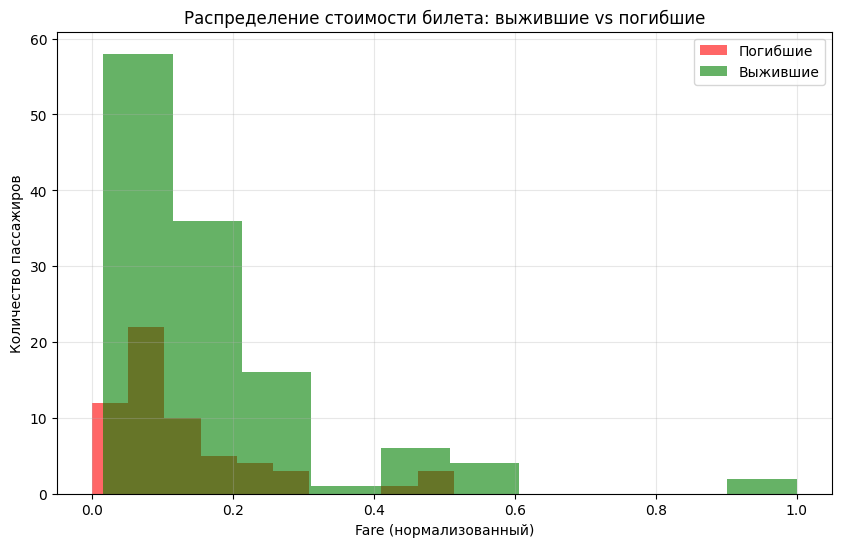

In [26]:
plt.figure(figsize=(10, 6))

plt.hist(frame[frame['Survived'] == 0]['Fare'],
         bins=10, alpha=0.6, color='red', label='Погибшие')
plt.hist(frame[frame['Survived'] == 1]['Fare'],
         bins=10, alpha=0.6, color='green', label='Выжившие')

plt.xlabel('Fare (нормализованный)')
plt.ylabel('Количество пассажиров')
plt.title('Распределение стоимости билета: выжившие vs погибшие')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

/tmp/ipykernel_7638/798273137.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = frame.groupby(['Fare_group', 'Survived']).size().unstack(fill_value=0)


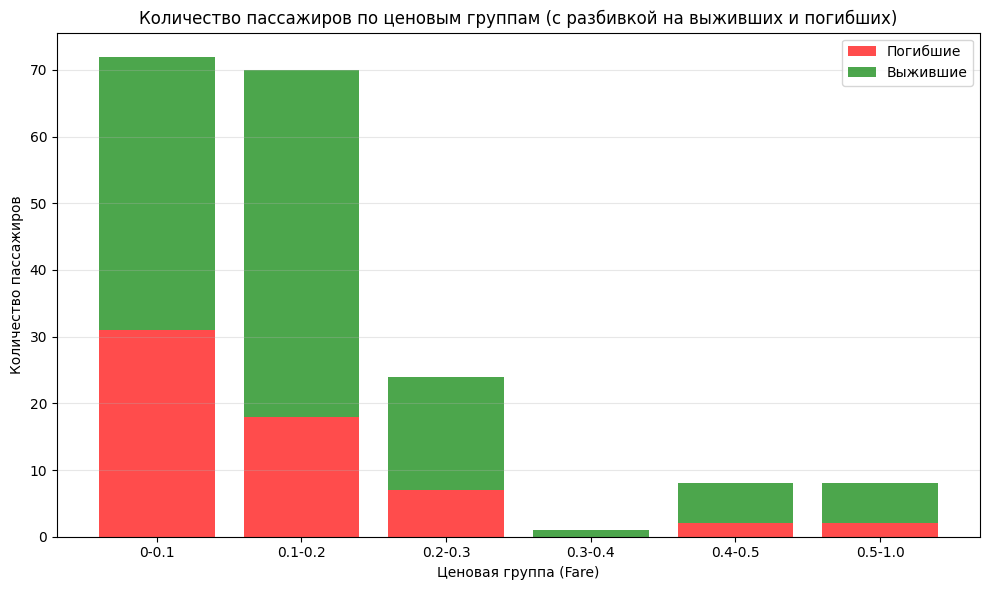

In [30]:
# Разбиваем Fare на интервалы по 0.1
bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 1.0]
labels = ['0-0.1', '0.1-0.2', '0.2-0.3', '0.3-0.4', '0.4-0.5', '0.5-1.0']
frame['Fare_group'] = pd.cut(frame['Fare'], bins=bins, labels=labels, include_lowest=True)

# Считаем количество выживших и погибших в каждой группе
counts = frame.groupby(['Fare_group', 'Survived']).size().unstack(fill_value=0)

# Строим stacked bar
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(counts.index, counts[0], label='Погибшие', color='red', alpha=0.7)
ax.bar(counts.index, counts[1], bottom=counts[0], label='Выжившие', color='green', alpha=0.7)

ax.set_xlabel('Ценовая группа (Fare)')
ax.set_ylabel('Количество пассажиров')
ax.set_title('Количество пассажиров по ценовым группам (с разбивкой на выживших и погибших)')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

Сформируйте набор признаков (X). Сформируйте вектор целевых значений (y).

In [31]:
X = frame[['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'male', 'female']]
y = frame['Survived']

print(f"X: {X.shape}")
print(f"y: {y.shape}")
print(X.head())
print(y.head())

X: (183, 7)
y: (183,)
             Pclass   Age  SibSp  Parch      Fare  male  female
PassengerId                                                    
2                 1  38.0      1      0  0.139136     0       1
4                 1  35.0      1      0  0.103644     0       1
7                 1  54.0      0      0  0.101229     1       0
11                3   4.0      1      1  0.032596     0       1
12                1  58.0      0      0  0.051822     0       1
PassengerId
2     1
4     1
7     0
11    1
12    1
Name: Survived, dtype: int64


**Предсказательная модель**

Разделите набор данных на два, одни для обучения модели другой для проверки. Тестовый набор должен содержать 25 процентов данных.

In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=67
)

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape},  y_test:  {y_test.shape}")
print(f"Доля теста: {len(X_test) / len(X):.2%}")

X_train: (137, 7), y_train: (137,)
X_test:  (46, 7),  y_test:  (46,)
Доля теста: 25.14%


Выполните обучение модели.

In [36]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)

print(f"Коэффициенты: {model.coef_}")
for name, coef in zip(X.columns, model.coef_[0]):
    print(f"{name:>8}: {coef:+.4f}")
print(f"Свободный член: {model.intercept_}")
print(f"Классы: {model.classes_}")

import numpy as np
for name, coef in zip(X.columns, model.coef_[0]):
    print(f"{name:>8}: coef = {coef:+.4f}, odds ratio = {np.exp(coef):.4f}")

Коэффициенты: [[-0.52283379 -0.02984916 -0.01965237 -0.30445278  0.43715646 -1.20367113
   1.203234  ]]
  Pclass: -0.5228
     Age: -0.0298
   SibSp: -0.0197
   Parch: -0.3045
    Fare: +0.4372
    male: -1.2037
  female: +1.2032
Свободный член: [2.88339205]
Классы: [0 1]
  Pclass: coef = -0.5228, odds ratio = 0.5928
     Age: coef = -0.0298, odds ratio = 0.9706
   SibSp: coef = -0.0197, odds ratio = 0.9805
   Parch: coef = -0.3045, odds ratio = 0.7375
    Fare: coef = +0.4372, odds ratio = 1.5483
    male: coef = -1.2037, odds ratio = 0.3001
  female: coef = +1.2032, odds ratio = 3.3309


**Проверка модели**

Выведите мартицу ошибок

Матрица ошибок:
[[ 8  7]
 [ 1 30]]


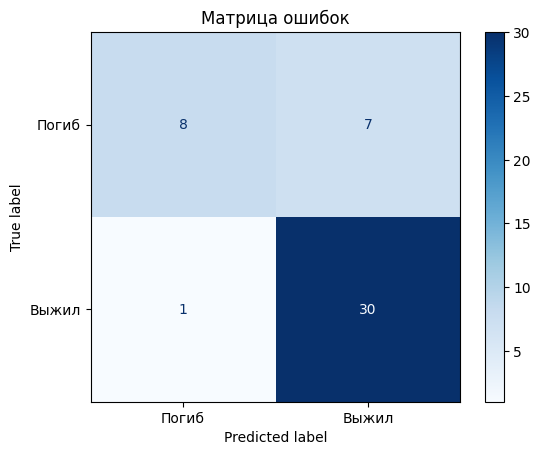

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
print("Матрица ошибок:")
print(cm)


ConfusionMatrixDisplay(cm, display_labels=['Погиб', 'Выжил']).plot(cmap='Blues')
plt.title('Матрица ошибок')
plt.show()

Расчитайте accuracy

In [42]:
accuracy = (30 + 8) / (1 + 8 + 7 + 30)
print(f"Точность составляет {accuracy * 100:.2f}%")

Точность составляет 82.61%


**Вывод:** Accuracy = 82.6% — хороший результат. Но матрица показывает перекос: модель лучше находит выживших (FN=1), чем погибших (FP=7). Это следствие дисбаланса в тестовой выборке.

**Вывод:** в ходе выполнения лабораторной работы была провелена классификация параметров, влиящих на выживание пассажиров титаника, а также построена предсказательная модель, основанная на данных параметрах.

**Ответы на контрольные вопросы:**

**Сформулируйте задачу классификации.**

Задача классификации: даны объекты с известными признаками и известной принадлежностью к классам; нужно построить алгоритм, который для нового объекта предскажет его класс.

**Перечислите типы классификации.**

Типы классификации: бинарная, многоклассовая (мультиклассовая), многоlabel (multi-label), несбалансированная. По стратегии обучения — one-vs-all, one-vs-one.

**В чем особенность несбалансированной классификации?**

Несбалансированная классификация: классы представлены неравномерно (один сильно преобладает). Модель склонна предсказывать большинство, accuracy обманчиво высока. Нужны precision/recall/F1, class_weight, oversampling/undersampling.

**В чем особенность мультиклассовой классификации?**

Мультиклассовая классификация: классов больше двух, каждый объект принадлежит ровно одному. Решается через one-vs-all, one-vs-one или напрямую (softmax).

**В чем особенность бинарной классификации?**

Бинарная классификация: ровно два класса (0/1, да/нет). Самый простой случай, но большинство алгоритмов сводятся к нему.

**В чем особенность классификации по нескольким меткам?**

Классификация по нескольким меткам: объект может принадлежать нескольким классам одновременно (например, теги статьи). Каждый класс — отдельная бинарная задача.

**Чем стратегия "Один против всех" отличается от стратегии "Один против одного"?**

One-vs-All vs One-vs-One: OvA обучает по одному бинарному классификатору на каждый класс («этот класс vs все остальные»). OvO обучает классификатор на каждую пару классов. Для N классов OvA — N моделей, OvO — N(N−1)/2 моделей. OvO точнее на маленьких данных, OvA быстрее.

**Что такое матрица ошибок (несоответствий)?**

Матрица ошибок: таблица 2×2 (для бинарной) с TN, FP, FN, TP — показывает, сколько объектов каждого реального класса отнесено к каждому предсказанному. Позволяет увидеть типы ошибок и посчитать метрики.Матрица ошибок: таблица 2×2 (для бинарной) с TN, FP, FN, TP — показывает, сколько объектов каждого реального класса отнесено к каждому предсказанному. Позволяет увидеть типы ошибок и посчитать метрики.

**Как рассчитывается Accuracy?**

Accuracy: доля правильных предсказаний: (TP + TN) / (TP + TN + FP + FN). Плохо работает при дисбалансе классов.

**Объясните алгоритм классификации K-ближайших соседей.**

K-ближайших соседей (KNN): для нового объекта находим K ближайших объектов обучающей выборки (по метрике расстояния, обычно евклидовой), смотрим их классы, выбираем самый частый (голосование большинством). Не требует обучения — просто запоминает данные. Чувствителен к масштабу признаков (нужна нормализация) и к выбору K.